# Compare FP32 and calibrated INT8 predictions

Train an MNIST digit-recognition network, then compare FP32 predictions with
quantized versions. First reproduce the calibrated mixed-precision reference;
then run a checked integer path with INT8 operands, INT32 totals and biases,
and integer rescaling. Its rescaling multiplier uses an INT64 temporary.

Choose **Runtime → Run all** in Colab. The first run downloads about 12 MB of
MNIST data and trains on the CPU. Training time is not accelerator latency.
This notebook contains all its code; no other notebook or GPU is needed.

After training, **1,000 reserved calibration images choose the intermediate
scale**. Keep that scale and the trained weights fixed while evaluating the
separate 10,000 test images. This increment preserves the calibration procedure.
Floating point is used for training, calibration, and converting normalized
pixels to INT8 at the input boundary. The integer prediction core starts with
those INT8 pixels and ends with INT32 digit scores; it needs no dequantization
to choose the largest score.

The recipe remains seed 530 and eight epochs. Results can vary slightly across
numerical libraries. Run all executes 11 data/FP32 checks, six calibration and
mixed-precision checks, and seven new integer-path checks.

Finally, the first 16 test images run through both simulated matrix layers in
both precisions, with independent result comparisons and three integration checks.
The complete notebook has 27 checks. Full-test accuracy is measured above these
small simulator checks; matrix-stage timing still excludes the other operations.


## 1 Images and known answers

MNIST contains small grayscale pictures of handwritten digits. Each picture is
**28 × 28 pixels**. Its **label** is the known digit, from 0 through 9.

The label is the answer we will later compare with the network's prediction.
The first gallery displays known labels. Network predictions appear later in this notebook.

The downloaded files contain pixel values and labels in a compact binary format
called IDX. The loader below checks file identity before decoding their headers
and contents. The checksum is a fingerprint of the published file.


In [1]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")

import gzip
import hashlib
from pathlib import Path
import struct
import sys
import unittest
import urllib.request

import numpy as np
%pip install matplotlib
import matplotlib.pyplot as plt

CACHE = Path("mnist-cache")
MIRROR = "https://ossci-datasets.s3.amazonaws.com/mnist/"
MNIST_FILES = {
    "train-images-idx3-ubyte.gz": "f68b3c2dcbeaaa9fbdd348bbdeb94873",
    "train-labels-idx1-ubyte.gz": "d53e105ee54ea40749a09fcbcd1e9432",
    "t10k-images-idx3-ubyte.gz": "9fb629c4189551a2d022fa330f9573f3",
    "t10k-labels-idx1-ubyte.gz": "ec29112dd5afa0611ce80d1b7f02629c",
}


def check_file_identity(payload, expected_md5):
    if hashlib.md5(payload).hexdigest() != expected_md5:
        raise ValueError("MNIST file checksum does not match the published file.")
    return payload


def fetch_mnist_file(filename):
    CACHE.mkdir(exist_ok=True)
    path = CACHE / filename
    if path.exists():
        payload = check_file_identity(path.read_bytes(), MNIST_FILES[filename])
    else:
        print("Downloading", filename)
        with urllib.request.urlopen(MIRROR + filename, timeout=30) as response:
            payload = check_file_identity(response.read(), MNIST_FILES[filename])
        path.write_bytes(payload)
    return payload


def normalize_pixels(pixels):
    return pixels.astype(np.float32) / np.float32(255)



def decode_images(payload):
    if len(payload) < 16:
        raise ValueError("Truncated image header.")
    magic, count, height, width = struct.unpack(">IIII", payload[:16])
    if magic != 2051 or (height, width) != (28, 28) or count < 1:
        raise ValueError("Invalid MNIST image header.")
    if len(payload) != 16 + count * height * width:
        raise ValueError("Image payload length does not match its header.")
    return np.frombuffer(payload, dtype=np.uint8, offset=16).reshape(count, 784)


def decode_labels(payload):
    if len(payload) < 8:
        raise ValueError("Truncated label header.")
    magic, count = struct.unpack(">II", payload[:8])
    if magic != 2049 or count < 1 or len(payload) != 8 + count:
        raise ValueError("Invalid MNIST label file.")
    labels = np.frombuffer(payload, dtype=np.uint8, offset=8)
    if np.any(labels > 9):
        raise ValueError("MNIST labels must be digits 0 through 9.")
    return labels

print("Verified MNIST loader ready.")


Verified MNIST loader ready.


## 2 Load the test set

Each original pixel is an integer from **0 to 255**: black through white. Dividing
by 255 represents that pixel on a **0 to 1** scale for the future network input.

A 28 × 28 picture contains `28 × 28 = 784` pixels. The loader stores each picture
as one row of 784 values. The same values can be reshaped into a picture again.

These files are the held-out test set. Training and calibration use
separate data below, so test labels remain a fair accuracy check.


In [2]:
image_file = fetch_mnist_file("t10k-images-idx3-ubyte.gz")
label_file = fetch_mnist_file("t10k-labels-idx1-ubyte.gz")
pixels = decode_images(gzip.decompress(image_file))
labels = decode_labels(gzip.decompress(label_file))
if pixels.shape != (10000, 784) or labels.shape != (10000,):
    raise ValueError("Expected 10,000 images with 784 pixels and one label each.")
inputs = normalize_pixels(pixels)
print("Images:", len(inputs))
print("Input table shape:", inputs.shape)
print("Labels:", len(labels))
print("Original pixel type:", pixels.dtype)
print("Normalized input type:", inputs.dtype)
print("Original pixel range:", int(pixels.min()), "to", int(pixels.max()))
print("Normalized range:", float(inputs.min()), "to", float(inputs.max()))


Images: 10000
Input table shape: (10000, 784)
Labels: 10000
Original pixel type: uint8
Normalized input type: float32
Original pixel range: 0 to 255
Normalized range: 0.0 to 1.0


## 3 Look at the images

These are the first twelve test images. Each title shows the label supplied with
the dataset. It is a known answer, not a guess made by our program.


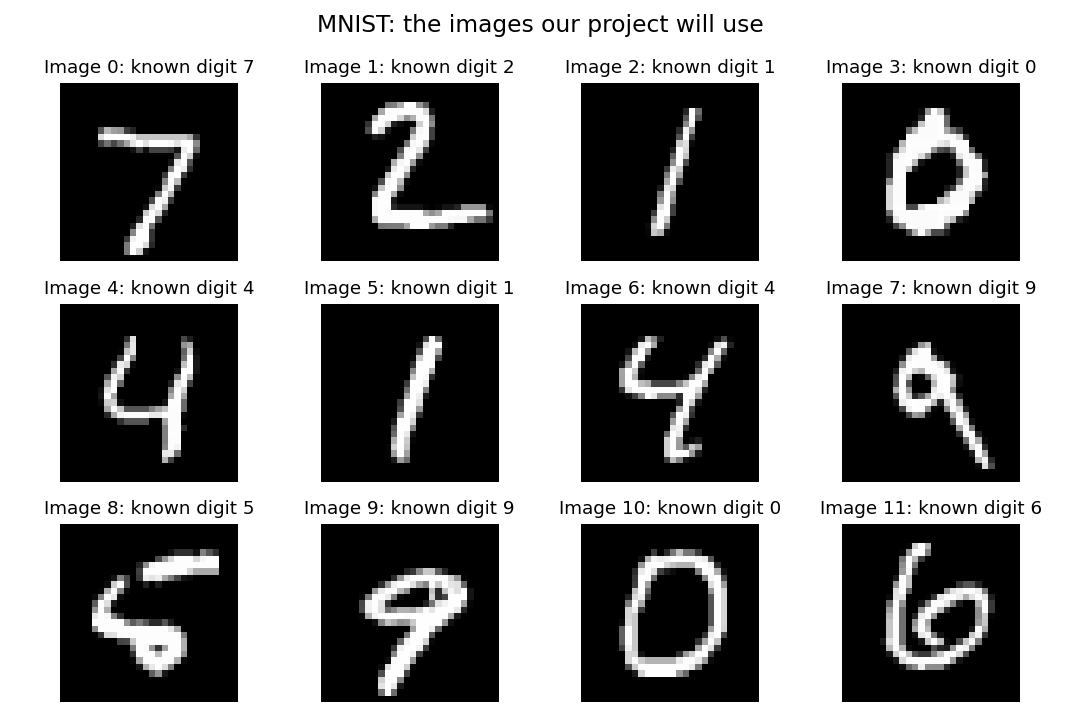

In [3]:
fig, axes = plt.subplots(3, 4, figsize=(9, 6))
for index, ax in enumerate(axes.flat):
    ax.imshow(inputs[index].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Image {index}: known digit {labels[index]}", fontsize=11)
    ax.axis("off")
fig.suptitle("MNIST: the images our project will use", fontsize=14)
fig.tight_layout()
plt.show()


## 4 Connect one picture to its numbers

Change `image_index` to another value from 0 through 9999 and rerun the next cell
to inspect a different image. A network will receive these pixel numbers and
calculate ten scores, one for each digit. That calculation follows below.


In [4]:
image_index = 0
if not 0 <= image_index < len(inputs):
    raise ValueError("image_index must be between 0 and 9999.")
picture = inputs[image_index].reshape(28, 28)
print("Image index:", image_index)
print("Known digit:", int(labels[image_index]))
print("Picture shape:", picture.shape)
print("Network input shape:", inputs[image_index:image_index + 1].shape)
print("Pixels above zero:", int(np.count_nonzero(picture)))
print("Middle row, rounded for display:")
print(np.round(picture[14], 2))


Image index: 0
Known digit: 7
Picture shape: (28, 28)
Network input shape: (1, 784)
Pixels above zero: 116
Middle row, rounded for display:
[0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
 0.   0.   0.23 0.98 1.   0.24 0.   0.   0.   0.   0.   0.   0.   0.  ]


## 5 Load separate training data

**Training** learns the network's weights from examples. **Inference** uses the
learned weights to guess a digit. Our accelerator project will study inference.

The original 60,000 training images are split with a fixed seed:

| Group | Images | Purpose |
|---|---:|---|
| Training | 54,000 | Learn weights |
| Validation | 5,000 | Monitor learning |
| Calibration | 1,000 | Choose the INT8 intermediate scale after training |

The 10,000 test images above stay outside training. A seed makes the random split
and initial weights repeatable within the same numerical setup.


In [5]:
def split_indices(seed=530):
    order = np.random.default_rng(seed).permutation(60000).astype(np.int32)
    return {"training": order[:54000], "validation": order[54000:59000],
            "calibration": order[59000:]}

train_image_file = fetch_mnist_file("train-images-idx3-ubyte.gz")
train_label_file = fetch_mnist_file("train-labels-idx1-ubyte.gz")
train_pixels = decode_images(gzip.decompress(train_image_file))
train_labels = decode_labels(gzip.decompress(train_label_file))
if train_pixels.shape != (60000, 784) or train_labels.shape != (60000,):
    raise ValueError("Expected 60,000 training images and labels.")
train_inputs = normalize_pixels(train_pixels)
indices = split_indices(seed=530)
for name, selected in indices.items():
    print(f"{name}: {len(selected):,} images")
print("Test images kept separate:", len(labels))


training: 54,000 images
validation: 5,000 images
calibration: 1,000 images
Test images kept separate: 10000


## 6 Define a small network

The network performs two matrix multiplications:

```text
784 pixel values → 64 intermediate values → 10 digit scores
```

Each layer multiplies inputs by learned **weights**, then adds learned offsets
called **biases**. Between layers, **ReLU** replaces negative values with zero.
The digit with the largest final score is the prediction. Scores are not
probabilities.

These matrix calculations will become work for our accelerator model later.
Here they run as FP32 NumPy operations. The training code below learns the weights
automatically; this increment does not model hardware cycles.


In [6]:
def forward_fp32(inputs, model):
    hidden = np.maximum(inputs @ model["w1"] + model["b1"], np.float32(0))
    logits = hidden @ model["w2"] + model["b2"]
    return hidden, logits


def train(inputs, labels, validation_inputs, validation_labels, *, epochs=8,
          hidden_units=64, seed=530, batch_size=128, learning_rate=0.001, progress=print):
    if epochs < 1 or hidden_units < 1 or batch_size < 1:
        raise ValueError("Epochs, hidden units, and batch size must be positive.")
    rng = np.random.default_rng(seed)
    model = {
        "w1": (rng.standard_normal((784, hidden_units)) * np.sqrt(2 / 784)).astype(np.float32),
        "b1": np.zeros(hidden_units, dtype=np.float32),
        "w2": (rng.standard_normal((hidden_units, 10)) * np.sqrt(2 / hidden_units)).astype(np.float32),
        "b2": np.zeros(10, dtype=np.float32),
    }
    first_moment = {key: np.zeros_like(value) for key, value in model.items()}
    second_moment = {key: np.zeros_like(value) for key, value in model.items()}
    step = 0
    history = []
    for epoch in range(1, epochs + 1):
        order = rng.permutation(len(inputs))
        loss_sum, correct = 0.0, 0
        for start in range(0, len(inputs), batch_size):
            indices = order[start:start + batch_size]
            x, y = inputs[indices], labels[indices]
            hidden, logits = forward_fp32(x, model)
            shifted = logits - logits.max(axis=1, keepdims=True)
            exponentials = np.exp(shifted)
            probabilities = exponentials / exponentials.sum(axis=1, keepdims=True)
            loss_sum += float(-np.log(np.maximum(probabilities[np.arange(len(y)), y],
                                                 np.float32(1e-8))).sum())
            correct += int(np.count_nonzero(logits.argmax(axis=1) == y))
            # Derivatives of cross entropy, the two dense layers, and ReLU.
            d_logits = probabilities.copy()
            d_logits[np.arange(len(y)), y] -= np.float32(1)
            d_logits *= np.float32(1 / len(y))
            d_hidden = d_logits @ model["w2"].T
            d_hidden[hidden <= 0] = 0
            gradients = {"w1": x.T @ d_hidden, "b1": d_hidden.sum(axis=0),
                         "w2": hidden.T @ d_logits, "b2": d_logits.sum(axis=0)}
            # Adam optimizer: maintain moving averages for each parameter.
            step += 1
            for key, parameter in model.items():
                first_moment[key] *= np.float32(0.9)
                first_moment[key] += np.float32(0.1) * gradients[key]
                second_moment[key] *= np.float32(0.999)
                second_moment[key] += np.float32(0.001) * gradients[key] ** 2
                corrected_first = first_moment[key] / np.float32(1 - 0.9**step)
                corrected_second = second_moment[key] / np.float32(1 - 0.999**step)
                parameter -= np.float32(learning_rate) * corrected_first / (
                    np.sqrt(corrected_second) + np.float32(1e-8))
        _, validation_logits = forward_fp32(validation_inputs, model)
        item = {"epoch": epoch, "training_loss": loss_sum / len(inputs),
                "training_accuracy": correct / len(inputs),
                "validation_accuracy": float(np.mean(validation_logits.argmax(axis=1) == validation_labels))}
        history.append(item)
        progress(f"Epoch {epoch}/{epochs}: loss={item['training_loss']:.4f}, "
                 f"training={100 * item['training_accuracy']:.2f}%, "
                 f"validation={100 * item['validation_accuracy']:.2f}%")
    return model, history

print("FP32 network and training routine are ready.")


FP32 network and training routine are ready.


## 7 Learn the weights

One **epoch** is a pass through the training data. This run uses eight epochs,
64 intermediate values, batches of 128 images, learning rate 0.001, and seed 530.
The network learns only from the training group. Validation accuracy is shown
after each epoch; test images are not used to update weights.

Keeping the recipe in the notebook avoids a large embedded model file. Run all
trains the model again; the original local checkpoint remains reference material.


In [7]:
TRAINING_SETTINGS = {"epochs": 8, "hidden_units": 64, "batch_size": 128,
                     "learning_rate": 0.001, "seed": 530}
fp_model, training_history = train(
    train_inputs[indices["training"]], train_labels[indices["training"]],
    train_inputs[indices["validation"]], train_labels[indices["validation"]],
    **TRAINING_SETTINGS,
)
print("First-layer weights:", fp_model["w1"].shape, fp_model["w1"].dtype)
print("Second-layer weights:", fp_model["w2"].shape, fp_model["w2"].dtype)


Epoch 1/8: loss=0.4293, training=88.49%, validation=93.50%
Epoch 2/8: loss=0.2004, training=94.32%, validation=94.94%
Epoch 3/8: loss=0.1549, training=95.56%, validation=95.72%
Epoch 4/8: loss=0.1277, training=96.36%, validation=96.18%
Epoch 5/8: loss=0.1089, training=96.83%, validation=96.90%
Epoch 6/8: loss=0.0933, training=97.35%, validation=96.84%
Epoch 7/8: loss=0.0814, training=97.69%, validation=97.20%
Epoch 8/8: loss=0.0719, training=97.97%, validation=97.16%
First-layer weights: (784, 64) float32
Second-layer weights: (64, 10) float32


## 8 Predict all 10,000 test images

Now use the trained weights without changing them. **Accuracy** is the number of
correct guesses divided by the number tested. Wrong guesses stay in the total.
This is the FP32 reference result for the later INT8 comparison.


In [8]:
prediction_batches = []
for start in range(0, len(inputs), 256):
    _, scores = forward_fp32(inputs[start:start + 256], fp_model)
    if scores.dtype != np.float32:
        raise RuntimeError("Expected FP32 score calculations.")
    prediction_batches.append(scores.argmax(axis=1))
fp_predictions = np.concatenate(prediction_batches)
fp_correct = int(np.count_nonzero(fp_predictions == labels))
fp_accuracy_percent = 100 * fp_correct / len(labels)
print(f"FP32: {fp_correct:,}/{len(labels):,} correct = {fp_accuracy_percent:.2f}%")
print("Incorrect predictions:", len(labels) - fp_correct)


FP32: 9,696/10,000 correct = 96.96%
Incorrect predictions: 304


## 9 Compare guesses with known labels

The titles now show both the known digit and the network's guess. Red marks a
mistake. The output for `image_index` connects the picture inspected earlier with
its new prediction.


Inspected image 0: known 7, FP32 guess 7


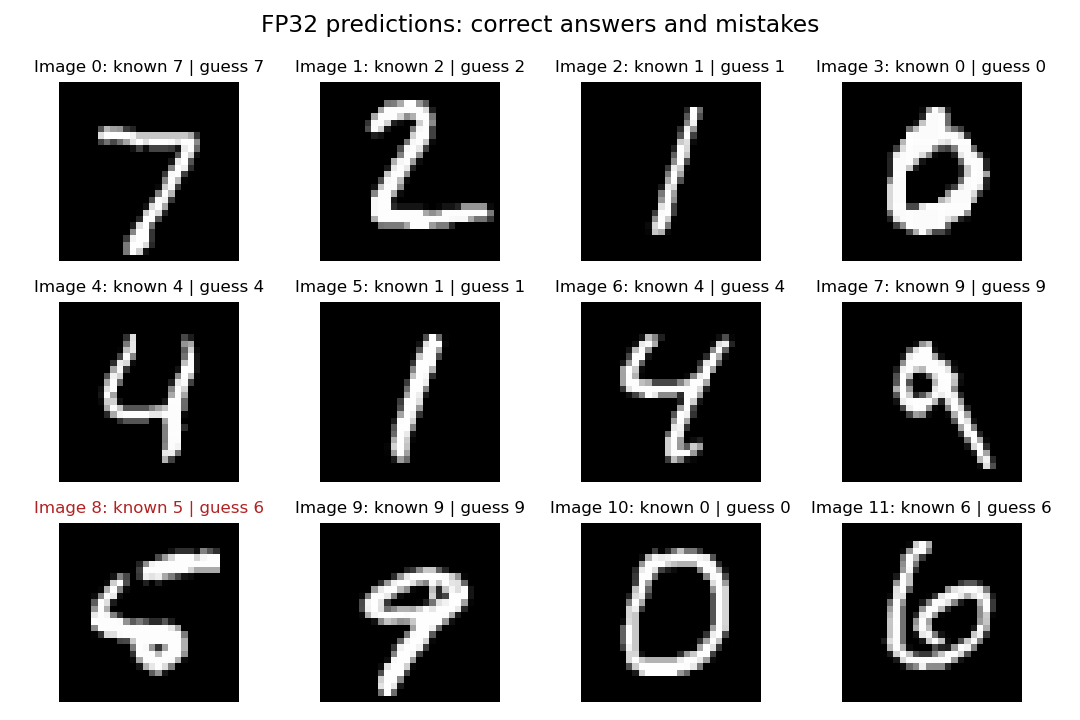

In [9]:
fig, axes = plt.subplots(3, 4, figsize=(9, 6))
for index, ax in enumerate(axes.flat):
    wrong = fp_predictions[index] != labels[index]
    ax.imshow(inputs[index].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Image {index}: known {labels[index]} | guess {fp_predictions[index]}",
                 color="firebrick" if wrong else "black", fontsize=10)
    ax.axis("off")
fig.suptitle("FP32 predictions: correct answers and mistakes", fontsize=14)
fig.tight_layout()
plt.show()
print(f"Inspected image {image_index}: known {labels[image_index]}, FP32 guess {fp_predictions[image_index]}")


## 10 Check the data and the FP32 baseline

The six data checks remain. Five additional checks cover a hand-calculated
network, training on a small known pattern, the reserved data split, real model
types and shapes, and complete test predictions. A broad 90% accuracy floor is
a sanity check for a functioning baseline, not a target used to tune the model.


In [10]:
class MnistDataTests(unittest.TestCase):
    def test_known_image_record(self):
        record = struct.pack(">IIII", 2051, 1, 28, 28) + bytes([255] * 784)
        decoded = decode_images(record)
        self.assertEqual(decoded.shape, (1, 784))
        self.assertEqual(decoded.dtype, np.uint8)
        self.assertTrue(np.all(decoded == 255))

    def test_reject_malformed_image_records(self):
        valid = struct.pack(">IIII", 2051, 1, 28, 28) + bytes(784)
        for record in (b"", valid[:-1], struct.pack(">IIII", 0, 1, 28, 28) + bytes(784)):
            with self.subTest(size=len(record)), self.assertRaises(ValueError):
                decode_images(record)

    def test_known_labels_and_reject_bad_records(self):
        valid = struct.pack(">II", 2049, 2) + bytes([3, 7])
        self.assertEqual(decode_labels(valid).tolist(), [3, 7])
        for record in (b"", valid[:-1], struct.pack(">II", 2049, 1) + bytes([10])):
            with self.subTest(size=len(record)), self.assertRaises(ValueError):
                decode_labels(record)

    def test_checksum_rejects_changed_content(self):
        expected = "5d41402abc4b2a76b9719d911017c592"
        self.assertEqual(check_file_identity(b"hello", expected), b"hello")
        with self.assertRaises(ValueError):
            check_file_identity(b"changed", expected)

    def test_known_normalized_values(self):
        normalized = normalize_pixels(np.array([[0, 127, 255]], dtype=np.uint8))
        self.assertEqual(normalized.dtype, np.float32)
        np.testing.assert_allclose(normalized, [[0.0, 0.4980392156862745, 1.0]], rtol=1e-6)

    def test_real_test_set_shape_and_labels(self):
        self.assertEqual(inputs.shape, (10000, 784))
        self.assertEqual(labels.shape, (10000,))
        self.assertTrue(np.all((labels >= 0) & (labels <= 9)))
        self.assertEqual(int(labels[0]), 7)
        self.assertEqual(int(labels[8]), 5)
        self.assertGreaterEqual(float(inputs.min()), 0)
        self.assertLessEqual(float(inputs.max()), 1)


class FP32BaselineTests(unittest.TestCase):
    def test_hand_calculated_forward_with_bias_and_relu(self):
        model = {
            "w1": np.array([[1, -1], [2, 1]], dtype=np.float32),
            "b1": np.array([0, -5], dtype=np.float32),
            "w2": np.array([[2, -1], [3, 4]], dtype=np.float32),
            "b2": np.array([1, 2], dtype=np.float32),
        }
        hidden, scores = forward_fp32(np.array([[1, 2]], dtype=np.float32), model)
        np.testing.assert_array_equal(hidden, [[5, 0]])
        np.testing.assert_array_equal(scores, [[11, -3]])
        self.assertEqual(hidden.dtype, np.float32)
        self.assertEqual(scores.dtype, np.float32)

    def test_training_learns_a_small_known_pattern(self):
        targets = np.tile(np.arange(10, dtype=np.uint8), 8)
        examples = np.zeros((80, 784), dtype=np.float32)
        examples[np.arange(80), targets] = 1
        learned, history = train(examples, targets, examples, targets, epochs=30,
                                 hidden_units=16, batch_size=80, learning_rate=0.03,
                                 progress=lambda message: None)
        self.assertLess(history[-1]["training_loss"], history[0]["training_loss"])
        self.assertGreaterEqual(history[-1]["validation_accuracy"], 0.9)
        self.assertTrue(all(value.dtype == np.float32 for value in learned.values()))

    def test_reserved_split_is_disjoint_complete_and_repeatable(self):
        self.assertEqual([len(indices[name]) for name in ("training", "validation", "calibration")],
                         [54000, 5000, 1000])
        np.testing.assert_array_equal(np.sort(np.concatenate(list(indices.values()))), np.arange(60000))
        repeated = split_indices(seed=530)
        for name in indices:
            np.testing.assert_array_equal(indices[name], repeated[name])

    def test_real_model_shapes_types_and_finite_scores(self):
        self.assertEqual(fp_model["w1"].shape, (784, 64))
        self.assertEqual(fp_model["w2"].shape, (64, 10))
        self.assertTrue(all(value.dtype == np.float32 for value in fp_model.values()))
        hidden, scores = forward_fp32(inputs[:16], fp_model)
        self.assertEqual(hidden.shape, (16, 64))
        self.assertEqual(scores.shape, (16, 10))
        self.assertEqual(scores.dtype, np.float32)
        self.assertTrue(np.all(np.isfinite(scores)))
        np.testing.assert_array_equal(scores.argmax(axis=1), fp_predictions[:16])

    def test_complete_test_predictions_and_baseline_sanity(self):
        self.assertEqual(fp_predictions.shape, (10000,))
        self.assertTrue(np.all((fp_predictions >= 0) & (fp_predictions <= 9)))
        self.assertEqual(fp_correct, int(np.sum(fp_predictions == labels)))
        self.assertGreaterEqual(fp_accuracy_percent, 90.0)

suite = unittest.TestSuite([
    unittest.defaultTestLoader.loadTestsFromTestCase(MnistDataTests),
    unittest.defaultTestLoader.loadTestsFromTestCase(FP32BaselineTests),
])
result = unittest.TextTestRunner(stream=sys.stdout, verbosity=2).run(suite)
if not result.wasSuccessful():
    raise AssertionError("A data or FP32 check failed; review the output above.")
print(f"All {result.testsRun} data and FP32 baseline checks passed.")


test_checksum_rejects_changed_content (__main__.MnistDataTests.test_checksum_rejects_changed_content) ... ok
test_known_image_record (__main__.MnistDataTests.test_known_image_record) ... ok
test_known_labels_and_reject_bad_records (__main__.MnistDataTests.test_known_labels_and_reject_bad_records) ... ok
test_known_normalized_values (__main__.MnistDataTests.test_known_normalized_values) ... ok
test_real_test_set_shape_and_labels (__main__.MnistDataTests.test_real_test_set_shape_and_labels) ... ok
test_reject_malformed_image_records (__main__.MnistDataTests.test_reject_malformed_image_records) ... ok
test_complete_test_predictions_and_baseline_sanity (__main__.FP32BaselineTests.test_complete_test_predictions_and_baseline_sanity) ... ok
test_hand_calculated_forward_with_bias_and_relu (__main__.FP32BaselineTests.test_hand_calculated_forward_with_bias_and_relu) ... ok
test_real_model_shapes_types_and_finite_scores (__main__.FP32BaselineTests.test_real_model_shapes_types_and_finite_scores) .

## Quantization setup

The next cells convert this trained FP32 model without retraining its weights.
The network's known 0–1 pixel range sets the input scale; learned weights set
their own scales; separate calibration images set the intermediate scale.
All scales use zero point 0. Weights use −127 through 127; nonnegative inputs
and ReLU outputs use 0 through 127. Rounding uses ties to even.

This notebook implements our own NumPy calculations. It does not run Brevitas
or claim matching framework results. Numerical prediction and accelerator
performance remain separate experiments.

**Design context:**
[https://xilinx.github.io/brevitas/v0.13.4/getting_started.html](https://xilinx.github.io/brevitas/v0.13.4/getting_started.html).

**MNIST file identities and mirror:**
[https://github.com/pytorch/vision/blob/main/torchvision/datasets/mnist.py](https://github.com/pytorch/vision/blob/main/torchvision/datasets/mnist.py).


## INT8 Post-Training Quantization
Next, we quantize the trained FP32 model to INT8 and evaluate its accuracy without retraining the network.

In [11]:
def quantize_weight_matrix(weights):
    weights = np.asarray(weights, dtype=np.float32)
    max_abs = np.max(np.abs(weights))
    scale = float(max_abs / 127.0) if max_abs else 1.0

    scaled = weights / scale
    clipped = np.clip(scaled, -127, 127)
    quantized = np.rint(clipped).astype(np.int8)
    return quantized, scale


w1_int8, w1_scale = quantize_weight_matrix(fp_model["w1"])
w2_int8, w2_scale = quantize_weight_matrix(fp_model["w2"])

for name, original, quantized, scale in (
    ("First-layer weights", fp_model["w1"], w1_int8, w1_scale),
    ("Second-layer weights", fp_model["w2"], w2_int8, w2_scale),
):
    print(f"{name}:")
    print(f"  FP32 shape: {original.shape}")
    print(f"  INT8 shape: {quantized.shape}")
    print(f"  FP32 min/max: {original.min():.6f} / {original.max():.6f}")
    print(f"  INT8 min/max: {quantized.min()} / {quantized.max()}")
    print(f"  Quantization scale: {scale:.10g}")

First-layer weights:
  FP32 shape: (784, 64)
  INT8 shape: (784, 64)
  FP32 min/max: -0.710802 / 0.458153
  INT8 min/max: -127 / 82
  Quantization scale: 0.005596863003
Second-layer weights:
  FP32 shape: (64, 10)
  INT8 shape: (64, 10)
  FP32 min/max: -1.009917 / 0.917818
  INT8 min/max: -127 / 115
  Quantization scale: 0.007952103465


## Fixed input scale

Pixel normalization already establishes the range 0–1, so the input scale is
**1/127**, independent of whichever images are tested. The helper rounds with
ties to even and clips to the signed range −127 through 127 before storage.


In [12]:
def quantize_int8(values, scale):
    if not np.isfinite(scale) or scale <= 0:
        raise ValueError("Quantization scale must be finite and positive.")
    values = np.asarray(values, dtype=np.float32)
    if not np.all(np.isfinite(values)):
        raise ValueError("Quantization values must be finite.")
    return np.rint(np.clip(values / scale, -127, 127)).astype(np.int8)


input_scale = 1.0 / 127.0
inputs_int8 = quantize_int8(inputs, input_scale)
print("FP32 input shape:", inputs.shape)
print("INT8 input shape:", inputs_int8.shape)
print("INT8 min/max:", inputs_int8.min(), "/", inputs_int8.max())
print(f"Fixed input scale from the known 0–1 range: {input_scale:.10g}")


FP32 input shape: (10000, 784)
INT8 input shape: (10000, 784)
INT8 min/max: 0 / 127
Fixed input scale from the known 0–1 range: 0.007874015748


## Choose the intermediate scale using calibration images

These 1,000 images come from the training archive's reserved group, not the test
set. Pass them through the quantized first layer and observe its nonnegative
outputs. Choose `largest observed output / 127`, or 1 for an all-zero output.
The running maximum or a single batch gives the same scale.

This configures the number representation; it does not train weights. Correct
labels are unnecessary. Once chosen, the scale stays fixed for all test batches.


In [13]:
def first_layer_int8(values, weights, bias, *, input_scale, weight_scale):
    quantized_inputs = quantize_int8(values, input_scale)
    totals = quantized_inputs.astype(np.int32) @ weights.astype(np.int32)
    linear = totals.astype(np.float32) * (input_scale * weight_scale) + bias
    return totals, linear


def calibrate_activation_scale(calibration_values, weights, bias, *, input_scale, weight_scale):
    _, linear = first_layer_int8(
        calibration_values, weights, bias,
        input_scale=input_scale, weight_scale=weight_scale,
    )
    maximum = float(np.maximum(linear, np.float32(0)).max())
    return maximum / 127.0 if maximum else 1.0


calibration_inputs = train_inputs[indices["calibration"]]
activation_scale = calibrate_activation_scale(
    calibration_inputs, w1_int8, fp_model["b1"],
    input_scale=input_scale, weight_scale=w1_scale,
)
print("Calibration images from the reserved training split:", len(calibration_inputs))
print("Calibration labels used: none")
print(f"Frozen intermediate scale: {activation_scale:.10g}")
print(f"Representable nonnegative range: 0 through {127 * activation_scale:.6f}")


Calibration images from the reserved training split: 1000
Calibration labels used: none
Frozen intermediate scale: 0.1018513807
Representable nonnegative range: 0 through 12.935125


## Mixed-precision reference: first layer

This reference uses integer matrix products, converts their totals to FP32, and
adds FP32 bias. The integer path added below will quantize the bias instead.


In [14]:
int32_linear_output, dequantized_linear_output = first_layer_int8(
    inputs, w1_int8, fp_model["b1"],
    input_scale=input_scale, weight_scale=w1_scale,
)
fp32_linear_output = inputs @ fp_model["w1"] + fp_model["b1"]
absolute_error = np.abs(dequantized_linear_output - fp32_linear_output)

print("INT32 output shape:", int32_linear_output.shape)
print("Dequantized output shape:", dequantized_linear_output.shape)
print("FP32 output shape:", fp32_linear_output.shape)
print(f"Mean absolute error: {absolute_error.mean():.8f}")
print(f"Maximum absolute error: {absolute_error.max():.8f}")


INT32 output shape: (10000, 64)
Dequantized output shape: (10000, 64)
FP32 output shape: (10000, 64)
Mean absolute error: 0.01300682
Maximum absolute error: 0.08711147


## Mixed-precision reference: hidden activation

Apply ReLU and use the frozen calibration scale. Values above its range are
clipped to 127. This reference still uses floating point for bias and rescaling;
the later integer path keeps the same scale but uses integer operations.


In [15]:
int8_relu_output = np.maximum(dequantized_linear_output, np.float32(0))
fp32_relu_output = np.maximum(fp32_linear_output, np.float32(0))
int8_activation = quantize_int8(int8_relu_output, activation_scale)
clipped_hidden_values = int(np.count_nonzero(int8_relu_output / activation_scale > 127))

dequantized_int8_activation = int8_activation.astype(np.float32) * activation_scale
activation_error = np.abs(fp32_relu_output - dequantized_int8_activation)

print("FP32 ReLU output shape:", fp32_relu_output.shape)
print("INT8 activation shape:", int8_activation.shape)
print("INT8 activation min/max:", int8_activation.min(), "/", int8_activation.max())
print(f"Frozen calibration scale: {activation_scale:.10g}")
print(f"Test hidden values above the calibrated range: {clipped_hidden_values:,} / {int8_relu_output.size:,}")
print(f"Mean absolute error: {activation_error.mean():.8f}")


FP32 ReLU output shape: (10000, 64)
INT8 activation shape: (10000, 64)
INT8 activation min/max: 0 / 127
Frozen calibration scale: 0.1018513807
Test hidden values above the calibrated range: 34 / 640,000
Mean absolute error: 0.01714387


## Mixed-precision reference: output and accuracy

The reference takes fixed scales as model settings. Both matrix products use
INT32 accumulation; biases and scale conversion remain FP32. Keep these results
for comparison with the integer path below. Test labels only grade predictions.


In [16]:
def forward_mixed_int8(values, model, quantized_model):
    _, linear = first_layer_int8(
        values, quantized_model["w1"], model["b1"],
        input_scale=quantized_model["input_scale"],
        weight_scale=quantized_model["w1_scale"],
    )
    hidden_int8 = quantize_int8(
        np.maximum(linear, np.float32(0)), quantized_model["activation_scale"]
    )
    totals = hidden_int8.astype(np.int32) @ quantized_model["w2"].astype(np.int32)
    logits = (totals.astype(np.float32)
              * (quantized_model["activation_scale"] * quantized_model["w2_scale"])
              + model["b2"])
    return totals, logits


quantized_model = {
    "w1": w1_int8, "w2": w2_int8,
    "input_scale": input_scale, "w1_scale": w1_scale, "w2_scale": w2_scale,
    "activation_scale": activation_scale,
}
int32_second_layer_output, int8_logits = forward_mixed_int8(inputs, fp_model, quantized_model)
int8_final_predictions = int8_logits.argmax(axis=1)
fp32_final_predictions = fp_predictions
fp32_test_accuracy = 100 * np.mean(fp32_final_predictions == labels)
int8_test_accuracy = 100 * np.mean(int8_final_predictions == labels)
accuracy_difference_pp = int8_test_accuracy - fp32_test_accuracy
prediction_disagreements = int(np.count_nonzero(fp32_final_predictions != int8_final_predictions))

print("INT32 second-layer output shape:", int32_second_layer_output.shape)
print("Quantized/dequantized logits shape:", int8_logits.shape)
print(f"FP32 test accuracy: {fp32_test_accuracy:.2f}%")
print(f"Quantized test accuracy: {int8_test_accuracy:.2f}%")
print(f"Accuracy difference (quantized - FP32): {accuracy_difference_pp:+.2f} percentage points")
print("FP32/quantized prediction disagreements:", prediction_disagreements)


INT32 second-layer output shape: (10000, 10)
Quantized/dequantized logits shape: (10000, 10)
FP32 test accuracy: 96.96%
Quantized test accuracy: 96.98%
Accuracy difference (quantized - FP32): +0.02 percentage points
FP32/quantized prediction disagreements: 15


## Check calibration and quantized predictions

Six new checks cover known rounding/clipping results, a hand-calculated scale
and all-zero fallback, a complete tiny prediction, the reserved calibration
source, batch-independent predictions with fixed scales, and exact comparison
with wider integer arithmetic. The original 11 data/FP32 checks ran above.


In [17]:
class QuantizationTests(unittest.TestCase):
    def test_known_rounding_clipping_and_invalid_scale(self):
        values = [-1000, -1.5, -0.5, 0.5, 1.5, 1000]
        result = quantize_int8(values, 1.0)
        np.testing.assert_array_equal(result, [-127, -2, 0, 0, 2, 127])
        self.assertEqual(result.dtype, np.int8)
        for scale in (0, -1, np.inf, np.nan):
            with self.subTest(scale=scale), self.assertRaises(ValueError):
                quantize_int8([1], scale)

    def test_hand_calculated_scale_and_zero_fallback(self):
        weights = np.array([[2], [-1]], dtype=np.int8)
        values = np.array([[1, 0], [0, 1]], dtype=np.float32)
        # Input scale .5 and weight scale 1 give ReLU outputs [2.5, 0].
        scale = calibrate_activation_scale(values, weights, np.array([.5], dtype=np.float32),
                                            input_scale=.5, weight_scale=1.0)
        self.assertAlmostEqual(scale, 2.5 / 127)
        zero_scale = calibrate_activation_scale(np.zeros((2, 2), dtype=np.float32),
                                                weights, np.array([-1], dtype=np.float32),
                                                input_scale=.5, weight_scale=1.0)
        self.assertEqual(zero_scale, 1.0)

    def test_hand_calculated_prediction_with_bias_and_relu(self):
        model = {"b1": np.array([0, -5], dtype=np.float32),
                 "b2": np.array([1, 2], dtype=np.float32)}
        quantized = {"w1": np.array([[1, -1], [2, 1]], dtype=np.int8),
                     "w2": np.array([[2, -1], [3, 4]], dtype=np.int8),
                     "input_scale": 1.0, "w1_scale": 1.0,
                     "w2_scale": 1.0, "activation_scale": 1.0}
        totals, logits = forward_mixed_int8([[1, 2]], model, quantized)
        np.testing.assert_array_equal(totals, [[10, -5]])
        np.testing.assert_array_equal(logits, [[11, -3]])
        self.assertEqual(totals.dtype, np.int32)
        self.assertEqual(logits.dtype, np.float32)

    def test_calibration_source_is_the_reserved_split(self):
        self.assertEqual(len(calibration_inputs), 1000)
        np.testing.assert_array_equal(calibration_inputs, train_inputs[indices["calibration"]])
        self.assertEqual(input_scale, 1 / 127)
        self.assertEqual(activation_scale, calibrate_activation_scale(
            calibration_inputs, w1_int8, fp_model["b1"],
            input_scale=input_scale, weight_scale=w1_scale))

    def test_test_images_batching_and_order_cannot_change_scales_or_scores(self):
        samples = inputs[:16]
        keys = ("input_scale", "w1_scale", "w2_scale", "activation_scale")
        before = tuple(quantized_model[key] for key in keys)
        _, together = forward_mixed_int8(samples, fp_model, quantized_model)
        alone = np.concatenate([forward_mixed_int8(row[None, :], fp_model, quantized_model)[1]
                                for row in samples])
        reversed_scores = forward_mixed_int8(samples[::-1], fp_model, quantized_model)[1][::-1]
        with_extreme_image = np.concatenate([samples, np.full((1, 784), 10, dtype=np.float32)])
        extra_scores = forward_mixed_int8(with_extreme_image, fp_model, quantized_model)[1][:16]
        for observed in (alone, reversed_scores, extra_scores):
            np.testing.assert_array_equal(observed, together)
        np.testing.assert_array_equal(together, int8_logits[:16])
        self.assertEqual(tuple(quantized_model[key] for key in keys), before)

    def test_real_int32_totals_match_wider_reference(self):
        # Wider arithmetic checks both layers independently for real inputs.
        x64 = inputs_int8[:16].astype(np.int64)
        first64 = x64 @ w1_int8.astype(np.int64)
        np.testing.assert_array_equal(int32_linear_output[:16], first64)
        linear = first64.astype(np.float32) * (input_scale * w1_scale) + fp_model["b1"]
        hidden = np.rint(np.clip(np.maximum(linear, 0) / activation_scale, 0, 127)).astype(np.int64)
        second64 = hidden @ w2_int8.astype(np.int64)
        np.testing.assert_array_equal(int32_second_layer_output[:16], second64)
        reference = second64.astype(np.float32) * (activation_scale * w2_scale) + fp_model["b2"]
        np.testing.assert_array_equal(int8_logits[:16], reference)
        for inner in (784, 64):
            self.assertLessEqual(inner * 127 * 127, np.iinfo(np.int32).max)
        self.assertEqual(int8_final_predictions.shape, (10000,))
        self.assertEqual(int8_test_accuracy, 100 * np.mean(int8_final_predictions == labels))

quantization_result = unittest.TextTestRunner(stream=sys.stdout, verbosity=2).run(
    unittest.defaultTestLoader.loadTestsFromTestCase(QuantizationTests)
)
if not quantization_result.wasSuccessful():
    raise AssertionError("A calibration or quantization check failed.")
print(f"All {quantization_result.testsRun} calibration and quantization checks passed.")


test_calibration_source_is_the_reserved_split (__main__.QuantizationTests.test_calibration_source_is_the_reserved_split) ... ok
test_hand_calculated_prediction_with_bias_and_relu (__main__.QuantizationTests.test_hand_calculated_prediction_with_bias_and_relu) ... ok
test_hand_calculated_scale_and_zero_fallback (__main__.QuantizationTests.test_hand_calculated_scale_and_zero_fallback) ... ok
test_known_rounding_clipping_and_invalid_scale (__main__.QuantizationTests.test_known_rounding_clipping_and_invalid_scale) ... ok
test_real_int32_totals_match_wider_reference (__main__.QuantizationTests.test_real_int32_totals_match_wider_reference) ... ok
test_test_images_batching_and_order_cannot_change_scales_or_scores (__main__.QuantizationTests.test_test_images_batching_and_order_cannot_change_scales_or_scores) ... ok

----------------------------------------------------------------------
Ran 6 tests in 0.047s

OK
All 6 calibration and quantization checks passed.


## Integer biases and rescaling

The first integer matrix product represents real values in units of
`input_scale × w1_scale`. Store its bias in those same units:

`INT32 bias = round(FP32 bias / (input_scale × w1_scale))`

The second bias uses `activation_scale × w2_scale`. Bias conversion happens
once during setup. Checks reject unsupported INT32 accumulator ranges before
matrix multiplication, rather than allowing silent wraparound.

Between layers, convert first-layer totals to the fixed hidden scale. During
setup, approximate `input_scale × w1_scale / activation_scale` as
`multiplier / 2**30`. During prediction, multiply the nonnegative integer total
by that integer multiplier, round ties to even, shift, and clip to 0–127.
The multiply uses a checked **INT64 temporary**; hidden storage stays INT8.
The chosen fixed shift supports positive multipliers below `2**31`; unsupported
ratios raise an error rather than silently becoming zero or overflowing.

The output scores stay INT32. Every output shares the same positive scale, so
its largest integer score identifies the same digit as dequantizing those scores.
This describes the number representation; bias/rescaling timing is still outside
our separate accelerator performance model.


In [18]:
def quantize_bias_int32(bias, scale):
    if not np.isfinite(scale) or scale <= 0:
        raise ValueError("Bias scale must be finite and positive.")
    bias = np.asarray(bias, dtype=np.float64)
    if not np.all(np.isfinite(bias)):
        raise ValueError("Bias values must be finite.")
    rounded = np.rint(bias / scale)
    limits = np.iinfo(np.int32)
    if np.any(rounded < limits.min) or np.any(rounded > limits.max):
        raise OverflowError("Quantized bias does not fit INT32.")
    return rounded.astype(np.int32)


def checked_integer_linear(values, weights, bias):
    if values.dtype != np.int8 or weights.dtype != np.int8 or bias.dtype != np.int32:
        raise TypeError("Expected INT8 operands and INT32 bias.")
    if (values.ndim != 2 or weights.ndim != 2 or bias.ndim != 1
            or values.shape[1] != weights.shape[0] or weights.shape[1] != len(bias)):
        raise ValueError("Layer dimensions do not match.")
    if np.any(values == -128) or np.any(weights == -128):
        raise ValueError("This model uses the narrow signed range -127 through 127.")
    # Absolute bounds cover every partial sum in any accumulation order.
    bound = 127 * np.abs(weights.astype(np.int64)).sum(axis=0)
    bias64 = bias.astype(np.int64)
    limits = np.iinfo(np.int32)
    if (np.any(bound > limits.max) or np.any(bias64 + bound > limits.max)
            or np.any(bias64 - bound < limits.min)):
        raise OverflowError("Layer cannot be guaranteed to accumulate and add bias in INT32.")
    raw = values.astype(np.int32) @ weights.astype(np.int32)
    return raw, raw + bias


def requantize_relu_integer(accumulators, multiplier, shift):
    if accumulators.dtype.kind != "i":
        raise TypeError("Rescaling requires signed integer totals.")
    if (not isinstance(multiplier, (int, np.integer))
            or not isinstance(shift, (int, np.integer))
            or not 0 < multiplier < 2**31 or not 1 <= shift <= 62):
        raise ValueError("Invalid integer rescaling multiplier or shift.")
    multiplier, shift = int(multiplier), int(shift)
    positive = np.maximum(accumulators.astype(np.int64), 0)
    if np.any(positive > np.iinfo(np.int64).max // multiplier):
        raise OverflowError("Rescaling multiply would exceed INT64.")
    products = positive * multiplier
    quotient = products >> shift
    remainder = products & ((1 << shift) - 1)
    halfway = 1 << (shift - 1)
    round_up = (remainder > halfway) | ((remainder == halfway) & ((quotient & 1) != 0))
    rounded = quotient + round_up
    clipped = int(np.count_nonzero(rounded > 127))
    return np.minimum(rounded, 127).astype(np.int8), clipped


def forward_integer_int8(values, model):
    raw1, biased1 = checked_integer_linear(values, model["w1"], model["b1"])
    hidden, clipped = requantize_relu_integer(biased1, model["multiplier"], model["shift"])
    raw2, scores = checked_integer_linear(hidden, model["w2"], model["b2"])
    return {"raw1": raw1, "biased1": biased1, "hidden": hidden,
            "raw2": raw2, "scores": scores, "hidden_clipped_values": clipped}


requant_shift = 30
rescale_ratio = input_scale * w1_scale / activation_scale
requant_multiplier = round(rescale_ratio * 2**requant_shift)
if not 0 < requant_multiplier < 2**31:
    raise ValueError("This scale ratio is outside the supported fixed-point range.")
integer_model = {
    "w1": w1_int8, "w2": w2_int8,
    "b1": quantize_bias_int32(fp_model["b1"], input_scale * w1_scale),
    "b2": quantize_bias_int32(fp_model["b2"], activation_scale * w2_scale),
    "multiplier": requant_multiplier, "shift": requant_shift,
}
print("Stored weights:", integer_model["w1"].dtype, integer_model["w2"].dtype)
print("Stored biases:", integer_model["b1"].dtype, integer_model["b2"].dtype)
print(f"Integer rescaling: multiply by {requant_multiplier}, then round and shift {requant_shift} bits")
print(f"Scale-ratio approximation error: {abs(rescale_ratio - requant_multiplier / 2**requant_shift):.3g}")


Stored weights: int8 int8
Stored biases: int32 int32
Integer rescaling: multiply by 464594, then round and shift 30 bits
Scale-ratio approximation error: 3.07e-10


## Evaluate the integer prediction path

Quantized pixels enter the integer core. It uses no floating-point biases or
rescaling. Report all three versions on the same 10,000 images; the mixed
reference remains useful because rounding biases changes the numerical model.
The learned weights and calibrated scales are unchanged.


In [19]:
integer_details = forward_integer_int8(inputs_int8, integer_model)
integer_predictions = integer_details["scores"].argmax(axis=1)
integer_correct = int(np.count_nonzero(integer_predictions == labels))
integer_accuracy_percent = 100 * integer_correct / len(labels)
integer_fp32_disagreements = int(np.count_nonzero(integer_predictions != fp_predictions))
integer_mixed_disagreements = int(np.count_nonzero(integer_predictions != int8_final_predictions))

print(f"FP32: {fp32_test_accuracy:.2f}%")
print(f"Calibrated mixed precision: {int8_test_accuracy:.2f}%")
print(f"Integer path: {integer_correct:,}/{len(labels):,} = {integer_accuracy_percent:.2f}%")
print("Integer/FP32 prediction disagreements:", integer_fp32_disagreements)
print("Integer/mixed prediction disagreements:", integer_mixed_disagreements)
print("Integer hidden values clipped:", integer_details["hidden_clipped_values"])
print("Hidden dtype:", integer_details["hidden"].dtype)
print("Final digit-score dtype:", integer_details["scores"].dtype)


FP32: 96.96%
Calibrated mixed precision: 96.98%
Integer path: 9,698/10,000 = 96.98%
Integer/FP32 prediction disagreements: 15
Integer/mixed prediction disagreements: 0
Integer hidden values clipped: 34
Hidden dtype: int8
Final digit-score dtype: int32


## Check the integer path

Known answers cover bias units, rounding ties, ReLU, clipping, and a complete
small prediction. Boundary checks cover INT32 bias/accumulation and the INT64
rescaling multiply. A separate Python-integer reference checks real images
without fixed-width overflow or the NumPy rescaling helper. Batch/order checks
verify that prediction keeps the numerical settings fixed.


In [20]:
class IntegerPathTests(unittest.TestCase):
    def test_bias_units_rounding_and_int32_boundaries(self):
        result = quantize_bias_int32([.25, .75, -.25, -.75], .5)
        np.testing.assert_array_equal(result, [0, 2, 0, -2])
        self.assertEqual(result.dtype, np.int32)
        limits = np.iinfo(np.int32)
        np.testing.assert_array_equal(quantize_bias_int32([limits.min, limits.max], 1),
                                      [limits.min, limits.max])
        for value in (limits.min - 1, limits.max + 1):
            with self.subTest(value=value), self.assertRaises(OverflowError):
                quantize_bias_int32([value], 1)

    def test_checked_matrix_bias_and_accumulator_bounds(self):
        x = np.array([[2, 3, 1]], dtype=np.int8)
        w = np.array([[4], [5], [6]], dtype=np.int8)
        raw, biased = checked_integer_linear(x, w, np.array([7], dtype=np.int32))
        np.testing.assert_array_equal(raw, [[29]])
        np.testing.assert_array_equal(biased, [[36]])
        zeros = np.zeros((1, 1), dtype=np.int8)
        for value in (np.iinfo(np.int32).min, np.iinfo(np.int32).max):
            bias = np.array([value], dtype=np.int32)
            np.testing.assert_array_equal(checked_integer_linear(zeros, zeros, bias)[1], [[value]])
            with self.assertRaises(OverflowError):
                checked_integer_linear(zeros, np.ones((1, 1), dtype=np.int8), bias)
        # Reject a potentially overflowing layer before running its dot product.
        with self.assertRaises(OverflowError):
            checked_integer_linear(np.zeros((1, 140000), dtype=np.int8),
                                   np.full((140000, 1), 127, dtype=np.int8),
                                   np.zeros(1, dtype=np.int32))

    def test_integer_rescaling_known_ties_relu_and_clipping(self):
        totals = np.array([-3, 0, 1, 3, 5, 7, 253, 255, 1000], dtype=np.int32)
        hidden, clipped = requantize_relu_integer(totals, 1, 1)
        np.testing.assert_array_equal(hidden, [0, 0, 0, 2, 2, 4, 126, 127, 127])
        self.assertEqual(hidden.dtype, np.int8)
        self.assertEqual(clipped, 2)
        self.assertLessEqual(abs(rescale_ratio - requant_multiplier / 2**requant_shift),
                             .5 / 2**requant_shift)

    def test_rescaling_rejects_bad_parameters_and_overflow(self):
        totals = np.array([1], dtype=np.int32)
        for multiplier, shift in [(0, 1), (2**31, 1), (1, 0), (1, 63), (1.5, 1)]:
            with self.subTest(parameters=(multiplier, shift)), self.assertRaises(ValueError):
                requantize_relu_integer(totals, multiplier, shift)
        with self.assertRaises(OverflowError):
            requantize_relu_integer(np.array([np.iinfo(np.int64).max], dtype=np.int64), 2, 1)
        with self.assertRaises(TypeError):
            requantize_relu_integer(np.array([1.0]), 1, 1)

    def test_complete_hand_calculated_integer_prediction(self):
        model = {"w1": np.array([[1, -1], [2, 1]], dtype=np.int8),
                 "b1": np.array([1, -5], dtype=np.int32),
                 "w2": np.array([[2, -1], [3, 4]], dtype=np.int8),
                 "b2": np.array([1, 2], dtype=np.int32), "multiplier": 1, "shift": 1}
        result = forward_integer_int8(np.array([[1, 2]], dtype=np.int8), model)
        np.testing.assert_array_equal(result["biased1"], [[6, -4]])
        np.testing.assert_array_equal(result["hidden"], [[3, 0]])
        np.testing.assert_array_equal(result["scores"], [[7, -1]])
        self.assertEqual(result["scores"].dtype, np.int32)

    def test_real_images_match_python_integer_reference(self):
        # Python integers and divmod provide an independent, unbounded reference.
        weights1, weights2 = w1_int8.tolist(), w2_int8.tolist()
        bias1, bias2 = integer_model["b1"].tolist(), integer_model["b2"].tolist()
        divisor = 2**requant_shift
        expected_scores = []
        expected_hidden = []
        for row in inputs_int8[:4].tolist():
            first = [sum(row[k] * weights1[k][j] for k in range(len(row))) + bias1[j]
                     for j in range(len(bias1))]
            hidden = []
            for total in first:
                quotient, remainder = divmod(max(total, 0) * requant_multiplier, divisor)
                if 2 * remainder > divisor or (2 * remainder == divisor and quotient % 2):
                    quotient += 1
                hidden.append(min(quotient, 127))
            scores = [sum(hidden[k] * weights2[k][j] for k in range(len(hidden))) + bias2[j]
                      for j in range(len(bias2))]
            expected_scores.append(scores)
            expected_hidden.append(hidden)
        np.testing.assert_array_equal(integer_details["hidden"][:4], expected_hidden)
        np.testing.assert_array_equal(integer_details["scores"][:4], expected_scores)

    def test_integer_predictions_independent_of_batch_and_order(self):
        samples = inputs_int8[:16]
        together = forward_integer_int8(samples, integer_model)["scores"]
        alone = np.concatenate([forward_integer_int8(row[None, :], integer_model)["scores"]
                                for row in samples])
        reversed_scores = forward_integer_int8(samples[::-1], integer_model)["scores"][::-1]
        with_extra = np.concatenate([samples, np.full((1, 784), 127, dtype=np.int8)])
        extra_scores = forward_integer_int8(with_extra, integer_model)["scores"][:16]
        for observed in (alone, reversed_scores, extra_scores):
            np.testing.assert_array_equal(observed, together)
        np.testing.assert_array_equal(together, integer_details["scores"][:16])
        self.assertEqual(integer_details["scores"].dtype, np.int32)
        self.assertEqual(integer_details["hidden"].dtype, np.int8)
        self.assertEqual(integer_predictions.shape, (10000,))

integer_result = unittest.TextTestRunner(stream=sys.stdout, verbosity=2).run(
    unittest.defaultTestLoader.loadTestsFromTestCase(IntegerPathTests)
)
if not integer_result.wasSuccessful():
    raise AssertionError("An integer-path check failed.")
print(f"All {integer_result.testsRun} integer-path checks passed.")
print(f"All {result.testsRun + quantization_result.testsRun + integer_result.testsRun} notebook checks passed.")


test_bias_units_rounding_and_int32_boundaries (__main__.IntegerPathTests.test_bias_units_rounding_and_int32_boundaries) ... ok
test_checked_matrix_bias_and_accumulator_bounds (__main__.IntegerPathTests.test_checked_matrix_bias_and_accumulator_bounds) ... ok
test_complete_hand_calculated_integer_prediction (__main__.IntegerPathTests.test_complete_hand_calculated_integer_prediction) ... ok
test_integer_predictions_independent_of_batch_and_order (__main__.IntegerPathTests.test_integer_predictions_independent_of_batch_and_order) ... ok
test_integer_rescaling_known_ties_relu_and_clipping (__main__.IntegerPathTests.test_integer_rescaling_known_ties_relu_and_clipping) ... ok
test_real_images_match_python_integer_reference (__main__.IntegerPathTests.test_real_images_match_python_integer_reference) ... ok
test_rescaling_rejects_bad_parameters_and_overflow (__main__.IntegerPathTests.test_rescaling_rejects_bad_parameters_and_overflow) ... ok

------------------------------------------------------

## Verify the real workload through the accelerator

The earlier network calculations used NumPy. Now run the **first 16 test
images and their actual trained weights** through the cycle-stepped simulator.
Each image runs separately through both matrix layers, in both precisions.
The second layer receives the first layer's actual simulated result after bias
and activation; these are not zero-filled timing placeholders.

The simulator definitions below match notebook 03. They are included here so
Run all needs no other notebook or project files. Keep its assumptions: eight
lanes, 256 KiB local storage, 32 bytes/cycle for local operand reads and external
transfers, and an assumed 100 MHz clock. Load, compute, and store do not overlap.
Weights reload for every layer and image; final matrix outputs occupy 32 bits.

Only matrix calculations and transfers contribute cycles. Bias, ReLU, rescaling,
and prediction selection are calculated and checked outside that timing model.
External-byte counts include matrix inputs, weights, and 32-bit matrix
outputs; they exclude biases and scale metadata. This verification does not
extend timing to those operations or transfers.


In [21]:
from dataclasses import asdict, dataclass, replace
import math
import struct

INT8_MIN, INT8_MAX = -128, 127

INT32_MIN, INT32_MAX = -(2**31), 2**31 - 1

def fp32(value):
    """Round to IEEE binary32 using Python's standard library."""
    return struct.unpack("f", struct.pack("f", value))[0]

def fp32_mac(accumulator, left, right):
    """Separate rounded FP32 multiply and add; fused multiply-add is not modeled."""
    return fp32(accumulator + fp32(left * right))

def matrix_shape(matrix):
    """Reject empty or ragged matrices rather than silently truncating data."""
    if not matrix or not matrix[0]:
        raise ValueError("A matrix must have at least one row and column.")
    columns = len(matrix[0])
    if any(len(row) != columns for row in matrix):
        raise ValueError("All matrix rows must have the same length.")
    return len(matrix), columns

def multiplication_shape(left, right):
    rows, inner = matrix_shape(left)
    right_rows, columns = matrix_shape(right)
    if inner != right_rows:
        raise ValueError("Left columns must equal right rows.")
    return rows, inner, columns

def validate_int8(value):
    if type(value) is not int:
        raise TypeError("INT8 operands must be integers, not floats or booleans.")
    if not INT8_MIN <= value <= INT8_MAX:
        raise ValueError(f"Operand {value} is outside the signed INT8 range.")

def checked_mac(accumulator, left, right):
    """One multiply-and-add; flag overflow rather than use Python's wider integers."""
    validate_int8(left)
    validate_int8(right)
    if type(accumulator) is not int:
        raise TypeError("The accumulator must be an integer.")
    if not INT32_MIN <= accumulator <= INT32_MAX:
        raise OverflowError("Initial accumulator is outside the INT32 range.")
    result = accumulator + left * right
    if not INT32_MIN <= result <= INT32_MAX:
        raise OverflowError("INT32 accumulation overflow.")
    return result

@dataclass(frozen=True)
class AcceleratorConfig:
    lanes: int = 4
    scratchpad_bytes: int = 4096
    local_read_bytes_per_cycle: int = 8
    external_bytes_per_cycle: int = 4

    def __post_init__(self):
        for name, value in asdict(self).items():
            if type(value) is not int or value <= 0:
                raise ValueError(f"{name} must be a positive integer.")
        if self.local_read_bytes_per_cycle < 2:
            raise ValueError("The local read bus must support at least one INT8 operand pair.")

@dataclass
class SimulationResult:
    output: list[list[int | float]]
    config: AcceleratorConfig
    metrics: dict
    trace: list[dict]

def simulate_matmul(left, right, config=None, *, record_trace=True, precision="int8"):
    config = config or AcceleratorConfig()
    rows, inner, columns = multiplication_shape(left, right)
    if precision not in ("int8", "fp32"):
        raise ValueError("Supported precisions are int8 and fp32.")
    operand_bytes = 1 if precision == "int8" else 4
    pair_bytes = 2 * operand_bytes
    if config.local_read_bytes_per_cycle < pair_bytes:
        raise ValueError(f"{precision} requires {pair_bytes} local read bytes per MAC.")
    for matrix in (left, right):
        for row in matrix:
            for value in row:
                if precision == "int8":
                    validate_int8(value)
                elif not math.isfinite(float(value)):
                    raise ValueError("FP32 operands must be finite.")
    if precision == "fp32":
        left = [[fp32(value) for value in row] for row in left]
        right = [[fp32(value) for value in row] for row in right]

    input_bytes = rows * inner * operand_bytes
    weight_bytes = inner * columns * operand_bytes
    output_bytes = rows * columns * 4  # INT32 or FP32 outputs, no INT8 requantization.
    required = input_bytes + weight_bytes + output_bytes
    if required > config.scratchpad_bytes:
        raise ValueError(
            f"Resident matrices need {required} scratchpad bytes; "
            f"only {config.scratchpad_bytes} provided. Tiling is not implemented yet."
        )

    output = [[0 if precision == "int8" else 0.0] * columns for _ in range(rows)]
    trace = []
    cycle = 0
    phase_cycles = {}

    def transfer(phase, byte_count):
        nonlocal cycle
        start = cycle
        remaining = byte_count
        while remaining:
            moved = min(remaining, config.external_bytes_per_cycle)
            cycle += 1
            if record_trace:
                trace.append({"cycle": cycle, "phase": phase, "bytes": moved})
            remaining -= moved
        phase_cycles[phase] = cycle - start

    transfer("load_inputs", input_bytes)
    transfer("load_weights", weight_bytes)
    compute_start = cycle
    blocked_lane_cycles = 0
    mac_count = 0
    outputs = [(row, column) for row in range(rows) for column in range(columns)]
    macs_per_cycle = min(config.lanes, config.local_read_bytes_per_cycle // pair_bytes)
    mac = checked_mac if precision == "int8" else fp32_mac

    for group_start in range(0, len(outputs), config.lanes):
        jobs = outputs[group_start:group_start + config.lanes]
        progress = [0] * len(jobs)
        cursor = 0
        while any(k < inner for k in progress):
            cycle += 1
            ready = []
            for offset in range(len(jobs)):
                lane = (cursor + offset) % len(jobs)
                if progress[lane] < inner:
                    ready.append(lane)
            issued = ready[:macs_per_cycle]
            blocked_lane_cycles += len(ready) - len(issued)
            operations = []
            for lane in issued:
                row, column = jobs[lane]
                k = progress[lane]
                a, b = left[row][k], right[k][column]
                output[row][column] = mac(output[row][column], a, b)
                progress[lane] += 1
                mac_count += 1
                if record_trace:
                    operations.append({
                        "lane": lane, "output": [row, column], "k": k,
                        "left": a, "right": b, "product": a * b,
                        "accumulator": output[row][column],
                        "finished": progress[lane] == inner,
                    })
            cursor = (issued[-1] + 1) % len(jobs)
            if record_trace:
                trace.append({"cycle": cycle, "phase": "compute", "macs": operations})

    phase_cycles["compute"] = cycle - compute_start
    transfer("store_outputs", output_bytes)
    compute_cycles = phase_cycles["compute"]
    metrics = {
        "precision": precision,
        "rows": rows, "inner": inner, "columns": columns,
        "macs": mac_count, "total_cycles": cycle,
        **{f"{phase}_cycles": count for phase, count in phase_cycles.items()},
        "input_bytes": input_bytes, "weight_bytes": weight_bytes,
        "output_bytes": output_bytes, "scratchpad_required_bytes": required,
        "external_bytes_transferred": input_bytes + weight_bytes + output_bytes,
        "local_operand_bytes_read": pair_bytes * mac_count,
        "bandwidth_blocked_lane_cycles": blocked_lane_cycles,
        "compute_lane_utilization": mac_count / (compute_cycles * config.lanes),
        "macs_per_total_cycle": mac_count / cycle,
    }
    return SimulationResult(output, config, metrics, trace)

print("Simulator ready: load inputs → load weights → compute → store outputs.")


WORKLOAD_CONFIG = AcceleratorConfig(
    lanes=8, scratchpad_bytes=256 * 1024,
    local_read_bytes_per_cycle=32, external_bytes_per_cycle=32,
)
WORKLOAD_CLOCK_HZ = 100_000_000
print("Real-workload configuration:", asdict(WORKLOAD_CONFIG))
print("Assumed clock:", WORKLOAD_CLOCK_HZ, "Hz")


Simulator ready: load inputs → load weights → compute → store outputs.
Real-workload configuration: {'lanes': 8, 'scratchpad_bytes': 262144, 'local_read_bytes_per_cycle': 32, 'external_bytes_per_cycle': 32}
Assumed clock: 100000000 Hz


## Compare each simulated layer with an independent calculation

INT8 matrix outputs must match wider NumPy INT64 products **exactly**. Check the
chained hidden values and final INT32 scores against the integer path above.

FP32 uses a separately rounded multiply and add in a fixed order. NumPy may
use a different reduction order. Compare each matrix output and the final scores
with `rtol=1e-5, atol=1e-4`, fixed before this run, and report the actual errors.
Predicted digits must still agree with the full-test reference predictions.

The table reports whether the simulator reproduces the reference calculation,
not whether every digit is classified correctly. A model can compute correctly
and still guess the wrong digit. The 16-image check is not a new accuracy study;
the full 10,000-image accuracy results above remain the evaluation.


In [22]:
def add_int32_bias_checked(raw, bias):
    wide = np.asarray(raw, dtype=np.int64) + bias.astype(np.int64)
    limits = np.iinfo(np.int32)
    if np.any(wide < limits.min) or np.any(wide > limits.max):
        raise OverflowError("Simulated matrix result plus bias exceeds INT32.")
    return wide.astype(np.int32)


def simulate_integer_core(values, model, config):
    first = simulate_matmul(values.tolist(), model["w1"].tolist(), config,
                            precision="int8", record_trace=False)
    biased1 = add_int32_bias_checked(first.output, model["b1"])
    hidden, clipped = requantize_relu_integer(biased1, model["multiplier"], model["shift"])
    second = simulate_matmul(hidden.tolist(), model["w2"].tolist(), config,
                             precision="int8", record_trace=False)
    scores = add_int32_bias_checked(second.output, model["b2"])
    return first, second, {"biased1": biased1, "hidden": hidden, "scores": scores,
                           "hidden_clipped_values": clipped}


def simulate_fp32_core(values, model, config):
    first = simulate_matmul(values.tolist(), model["w1"].tolist(), config,
                            precision="fp32", record_trace=False)
    hidden = np.maximum(np.asarray(first.output, dtype=np.float32) + model["b1"], np.float32(0))
    second = simulate_matmul(hidden.tolist(), model["w2"].tolist(), config,
                             precision="fp32", record_trace=False)
    scores = np.asarray(second.output, dtype=np.float32) + model["b2"]
    return first, second, {"hidden": hidden, "scores": scores}


FP32_RTOL, FP32_ATOL = 1e-5, 1e-4
verified_indices = tuple(range(16))
workload_verification_rows = []
workload_integer_reference = integer_details

for image_index in verified_indices:
    x = inputs[image_index:image_index + 1]
    qx = inputs_int8[image_index:image_index + 1]
    int1, int2, int_values = simulate_integer_core(qx, integer_model, WORKLOAD_CONFIG)
    np.testing.assert_array_equal(int1.output, qx.astype(np.int64) @ w1_int8.astype(np.int64))
    np.testing.assert_array_equal(int2.output,
                                  int_values["hidden"].astype(np.int64) @ w2_int8.astype(np.int64))
    for key in ("biased1", "hidden", "scores"):
        np.testing.assert_array_equal(int_values[key], workload_integer_reference[key][image_index:image_index + 1])

    fp1, fp2, fp_values = simulate_fp32_core(x, fp_model, WORKLOAD_CONFIG)
    ref1 = x @ fp_model["w1"]
    # Isolate second-layer multiplication using the simulated first-layer values.
    ref2 = fp_values["hidden"] @ fp_model["w2"]
    _, ref_scores = forward_fp32(x, fp_model)
    for observed, expected in [(fp1.output, ref1), (fp2.output, ref2), (fp_values["scores"], ref_scores)]:
        np.testing.assert_allclose(observed, expected, rtol=FP32_RTOL, atol=FP32_ATOL)

    fp_guess = int(fp_values["scores"].argmax(axis=1)[0])
    int_guess = int(int_values["scores"].argmax(axis=1)[0])
    assert fp_guess == int(fp_predictions[image_index])
    assert int_guess == int(integer_predictions[image_index])
    row = {
        "image_index": image_index, "label": int(labels[image_index]),
        "fp32_prediction": fp_guess, "int8_prediction": int_guess,
        "fp32_layer1_max_abs_error": float(np.max(np.abs(np.asarray(fp1.output) - ref1))),
        "fp32_layer2_max_abs_error": float(np.max(np.abs(np.asarray(fp2.output) - ref2))),
        "fp32_scores_max_abs_error": float(np.max(np.abs(fp_values["scores"] - ref_scores))),
        "fp32_cycles": fp1.metrics["total_cycles"] + fp2.metrics["total_cycles"],
        "int8_cycles": int1.metrics["total_cycles"] + int2.metrics["total_cycles"],
        "fp32_compute_cycles": fp1.metrics["compute_cycles"] + fp2.metrics["compute_cycles"],
        "int8_compute_cycles": int1.metrics["compute_cycles"] + int2.metrics["compute_cycles"],
        "fp32_external_bytes": fp1.metrics["external_bytes_transferred"] + fp2.metrics["external_bytes_transferred"],
        "int8_external_bytes": int1.metrics["external_bytes_transferred"] + int2.metrics["external_bytes_transferred"],
    }
    workload_verification_rows.append(row)

print("Image | Known digit | FP32 guess | INT8 guess | Reference checks")
for row in workload_verification_rows:
    print(f"{row['image_index']:5d} | {row['label']:11d} | {row['fp32_prediction']:10d} | "
          f"{row['int8_prediction']:10d} | passed")
print(f"Verified {len(verified_indices)} real images, two layers, and both precisions.")
print("FP32 maximum layer-1 absolute error:", max(r["fp32_layer1_max_abs_error"] for r in workload_verification_rows))
print("FP32 maximum layer-2 absolute error:", max(r["fp32_layer2_max_abs_error"] for r in workload_verification_rows))
print("FP32 maximum final-score absolute error:", max(r["fp32_scores_max_abs_error"] for r in workload_verification_rows))
for precision in ("fp32", "int8"):
    cycles = workload_verification_rows[0][precision + "_cycles"]
    compute = workload_verification_rows[0][precision + "_compute_cycles"]
    print(f"{precision.upper()} per-image matrix stages: {cycles:,} cycles = "
          f"{compute:,} compute + {cycles - compute:,} transfer; "
          f"{cycles / WORKLOAD_CLOCK_HZ * 1e6:.2f} microseconds at the assumed clock")
print("These times exclude bias, activation, rescaling, and choosing a digit.")


Image | Known digit | FP32 guess | INT8 guess | Reference checks
    0 |           7 |          7 |          7 | passed
    1 |           2 |          2 |          2 | passed
    2 |           1 |          1 |          1 | passed
    3 |           0 |          0 |          0 | passed
    4 |           4 |          4 |          4 | passed
    5 |           1 |          1 |          1 | passed
    6 |           4 |          4 |          4 | passed
    7 |           9 |          9 |          9 | passed
    8 |           5 |          6 |          6 | passed
    9 |           9 |          9 |          9 | passed
   10 |           0 |          0 |          0 | passed
   11 |           6 |          6 |          6 | passed
   12 |           9 |          9 |          9 | passed
   13 |           0 |          0 |          0 | passed
   14 |           1 |          1 |          1 | passed
   15 |           5 |          5 |          5 | passed
Verified 16 real images, two layers, and both precision

## Check the connections and hardware settings

Three additional tests use small hand-calculated two-layer networks in each
precision and a real image under four versus eight lanes. They check bias,
ReLU, and rescaling between the simulated layers, and verify that changing the
hardware schedule changes cycles while preserving the integer answer.

The 32-byte local read budget allows at most 16 INT8 or four FP32 MACs/cycle.
Adding 32 INT8 lanes therefore cannot improve compute time unless that local
budget also increases. External bandwidth separately changes load/store costs.


In [23]:
class WorkloadModelTests(unittest.TestCase):
    def test_hand_calculated_integer_layers_are_chained(self):
        model = {"w1": np.array([[1, -1], [2, 1]], dtype=np.int8),
                 "b1": np.array([1, -5], dtype=np.int32),
                 "w2": np.array([[2, -1], [3, 4]], dtype=np.int8),
                 "b2": np.array([1, 2], dtype=np.int32), "multiplier": 1, "shift": 1}
        first, second, values = simulate_integer_core(np.array([[1, 2]], dtype=np.int8),
                                                       model, WORKLOAD_CONFIG)
        np.testing.assert_array_equal(first.output, [[5, 1]])
        np.testing.assert_array_equal(values["hidden"], [[3, 0]])
        np.testing.assert_array_equal(second.output, [[6, -3]])
        np.testing.assert_array_equal(values["scores"], [[7, -1]])

    def test_hand_calculated_fp32_layers_are_chained(self):
        model = {"w1": np.array([[1, -1], [2, 1]], dtype=np.float32),
                 "b1": np.array([0, -5], dtype=np.float32),
                 "w2": np.array([[2, -1], [3, 4]], dtype=np.float32),
                 "b2": np.array([1, 2], dtype=np.float32)}
        first, second, values = simulate_fp32_core(np.array([[1, 2]], dtype=np.float32),
                                                    model, WORKLOAD_CONFIG)
        np.testing.assert_array_equal(first.output, [[5, 1]])
        np.testing.assert_array_equal(values["hidden"], [[5, 0]])
        np.testing.assert_array_equal(second.output, [[10, -5]])
        np.testing.assert_array_equal(values["scores"], [[11, -3]])

    def test_real_integer_answer_survives_a_lane_count_change(self):
        first, second, values = simulate_integer_core(inputs_int8[:1], integer_model,
                                                       replace(WORKLOAD_CONFIG, lanes=4))
        np.testing.assert_array_equal(values["scores"], workload_integer_reference["scores"][:1])
        # Four lanes need 12,736 compute + 1,625 transfer cycles for these shapes.
        self.assertEqual(first.metrics["total_cycles"] + second.metrics["total_cycles"], 14361)
        self.assertEqual(workload_verification_rows[0]["int8_cycles"], 8025)
        with self.assertRaises(OverflowError):
            add_int32_bias_checked([[np.iinfo(np.int32).max]], np.array([1], dtype=np.int32))

workload_result = unittest.TextTestRunner(stream=sys.stdout, verbosity=2).run(
    unittest.defaultTestLoader.loadTestsFromTestCase(WorkloadModelTests)
)
if not workload_result.wasSuccessful():
    raise AssertionError("A real-workload integration check failed.")
print(f"All {workload_result.testsRun} workload-model checks passed.")
print(f"All {result.testsRun + quantization_result.testsRun + integer_result.testsRun + workload_result.testsRun} notebook checks passed.")


test_hand_calculated_fp32_layers_are_chained (__main__.WorkloadModelTests.test_hand_calculated_fp32_layers_are_chained) ... ok
test_hand_calculated_integer_layers_are_chained (__main__.WorkloadModelTests.test_hand_calculated_integer_layers_are_chained) ... ok
test_real_integer_answer_survives_a_lane_count_change (__main__.WorkloadModelTests.test_real_integer_answer_survives_a_lane_count_change) ... ok

----------------------------------------------------------------------
Ran 3 tests in 0.027s

OK
All 3 workload-model checks passed.
All 27 notebook checks passed.


## Export accuracy and verification results

Run all writes `results/mnist-results.json` with full-test correct counts,
training settings, calibrated scales, model and prediction fingerprints, and
the 16 real-value simulation checks. These are measured counts from this run;
notebook 06 calculates accuracy percentages from them.

In Colab this cell downloads the JSON file. Run notebook 03 to obtain
`accelerator-results.json`, then upload both exports in notebook 06. Each
producer notebook remains independently runnable. Checked repository copies
can also reproduce the plots without training again.


In [24]:
import hashlib
import json
from pathlib import Path
import platform

if not all(check.wasSuccessful() for check in
           (result, quantization_result, integer_result, workload_result)):
    raise AssertionError("All numerical checks must pass before exporting results.")
model_digest = hashlib.sha256()
for name in sorted(fp_model):
    model_digest.update(name.encode())
    model_digest.update(fp_model[name].tobytes())
mnist_export = {
    "schema_version": 1, "kind": "mnist", "producer": "05-int8-mnist-inference.ipynb",
    "environment": {"python": platform.python_version(), "numpy": np.__version__},
    "network_dimensions": [fp_model["w1"].shape[0], fp_model["w1"].shape[1], fp_model["w2"].shape[1]],
    "dataset_md5": MNIST_FILES, "training_settings": TRAINING_SETTINGS,
    "fp32_parameter_sha256": model_digest.hexdigest(),
    "prediction_sha256": {
        "fp32": hashlib.sha256(fp_predictions.astype(np.uint8).tobytes()).hexdigest(),
        "int8": hashlib.sha256(integer_predictions.astype(np.uint8).tobytes()).hexdigest(),
    },
    "accuracy": {
        "test_images": len(labels), "fp32_correct": int(np.count_nonzero(fp_predictions == labels)),
        "mixed_correct": int(np.count_nonzero(int8_final_predictions == labels)),
        "int8_correct": integer_correct, "fp32_int8_disagreements": integer_fp32_disagreements,
    },
    "quantization": {
        "calibration_images": len(calibration_inputs), "calibration_source": "reserved_training_split",
        "zero_point": 0, "weight_range": [-127, 127], "relu_range": [0, 127],
        "input_scale": input_scale, "w1_scale": w1_scale, "w2_scale": w2_scale,
        "activation_scale": activation_scale, "bias_dtype": "int32", "rescale_temporary_dtype": "int64",
        "multiplier": requant_multiplier, "shift": requant_shift,
        "hidden_clipped_values": integer_details["hidden_clipped_values"],
    },
    "verification": {
        "timing_scope": "matrix_stages_only", "config": asdict(WORKLOAD_CONFIG),
        "clock_hz": WORKLOAD_CLOCK_HZ, "fp32_rtol": FP32_RTOL, "fp32_atol": FP32_ATOL,
        "rows": workload_verification_rows,
    },
    "checks_passed": sum(check.testsRun for check in
                         (result, quantization_result, integer_result, workload_result)),
}
export_path = Path("results/mnist-results.json")
export_path.parent.mkdir(exist_ok=True)
export_path.write_text(json.dumps(mnist_export, indent=2, allow_nan=False) + "\n")
print("Wrote", export_path)
print("Exported accuracy counts for", len(labels), "images and",
      len(workload_verification_rows), "real-value simulation checks.")
try:
    from google.colab import files
except ImportError:
    print("Use this file with accelerator-results.json in notebook 06.")
else:
    files.download(str(export_path))


Wrote results/mnist-results.json
Exported accuracy counts for 10000 images and 16 real-value simulation checks.
Use this file with accelerator-results.json in notebook 06.
